In [1]:
import eu9_osm
import geopandas as gpd
import matplotlib.pyplot as plt
import textwrap

In [2]:
place = "Alfama"
buildings = eu9_osm.features_from_place(place, tags={"building": True})
buildings = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index()

In [3]:
churches = buildings[buildings["building"].isin(["church", "cathedral", "chapel"])].reset_index(drop=True)
churches = churches[~churches["name"].isna()]

In [4]:
crs = "EPSG:3763"
churches_3763 = churches.to_crs(crs)
churches_3763["area_m2"] = churches_3763.geometry.area

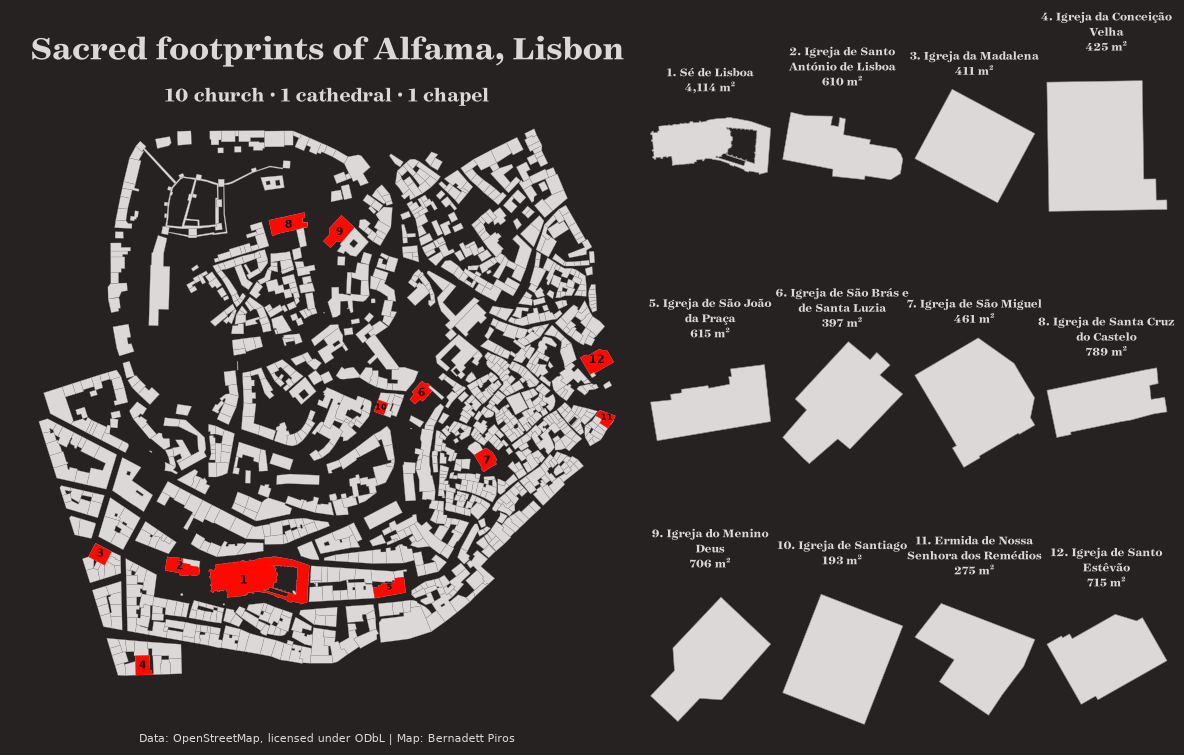

In [5]:
fig = plt.figure(figsize=(15, 10), facecolor="#252221")

gs = fig.add_gridspec(nrows=3, ncols=2, width_ratios=[1.2, 1], wspace=0)

# Left side
ax0 = fig.add_subplot(gs[:, 0])
ax0.set_facecolor("#252221")

buildings.plot(ax=ax0, color="#dbd8d7", edgecolor="#949190", lw=0.2)

churches.plot(ax=ax0, color="#FF0801")

for i, (index, row) in enumerate(churches.iterrows()):

    point = row.geometry.representative_point()    

    ax0.text(point.x, point.y, str(i + 1), color="black",  
             size=6 if i in [4, 9, 10] else 8, fontweight="bold", ha="center", va="center")

ax0.axis("off")

# Right side
right_gs = gs[:, 1].subgridspec(nrows=3, ncols=4, wspace=0, hspace=0)

axes = [
    fig.add_subplot(right_gs[i, j])
    for i in range(3)
    for j in range(4)
]

for i, (ax, (idx, row)) in enumerate(zip(axes, churches_3763.iterrows())):

    ax.set_facecolor("#252221")
    
    churches_3763.loc[[idx]].plot(ax=ax, facecolor="#dbd8d7", edgecolor="#949190", lw=0.4)
    
    name = textwrap.fill(str(row["name"]), width=20)

    ax.set_title(
        f"{i + 1}. {name}\n"
        f"{row["area_m2"]:,.0f} m²",
        color="#dbd8d7", size=9, fontfamily="Surveyor Text Bold")
    
    ax.axis("off")

ax0.text(0.5, 1.07, "Sacred footprints of Alfama, Lisbon", color="#dbd8d7", size=25,
         fontfamily="Surveyor Text Bold", ha="center", transform=ax0.transAxes,)

counts = churches["building"].value_counts()

title = " · ".join( f"{count} {name}" for name, count in counts.items())

ax0.text(0.5, 1, title, color="#dbd8d7", size=15, fontfamily="Surveyor Text Bold", ha="center", transform=ax0.transAxes,)

ax0.text( 0.5, -0.05,
          "Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros",
          color="#dbd8d7", size=8, ha="center", va="top",
          transform=ax0.transAxes)          

plt.show()

#fig.savefig("sacred_footprints.png", bbox_inches="tight", pad_inches=0.2)